# Evaluate and compare baseline vs augmented predictors

Evaluates the already-trained baseline and augmented cosine predictors on the official MVTec AD test images. It does not train, calibrate on test data, select checkpoints, or change inference behavior. Test latents are stored separately under `data/cache/latents_test`; raw score maps and the repository's production metrics are used throughout.

Image decision labels are intentionally omitted: this is an uncalibrated/default inference comparison, not a threshold-calibration exercise. Image AUROC, pixel AUROC, and AUPRO are ranking metrics and use no decision threshold.

## 1. Imports and configuration

In [1]:
from dataclasses import asdict
from pathlib import Path
import hashlib
import json
import math
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (path for path in candidates if (path / 'configs').is_dir() and (path / 'src').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository or its notebooks directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

CATEGORIES = ('bottle', 'capsule', 'hazelnut')
PREDICTOR_TYPES = ('baseline', 'augmented')
ENCODER_CHECKPOINT = PROJECT_ROOT / 'checkpoints' / 'IN22K-vit.g.16-600e.pth.tar'
OFFICIAL_IJEPA_ROOT = PROJECT_ROOT / 'external' / 'ijepa'
BASELINE_CHECKPOINT_ROOT = PROJECT_ROOT / 'checkpoints' / 'predictors'
AUGMENTED_CHECKPOINT_ROOT = PROJECT_ROOT / 'checkpoints' / 'predictors_augmented'
CHECKPOINT_ROOTS = {
    'baseline': BASELINE_CHECKPOINT_ROOT,
    'augmented': AUGMENTED_CHECKPOINT_ROOT,
}
TEST_CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'latents_test'
OUTPUT_ROOT = PROJECT_ROOT / 'results' / 'evaluation'
FIGURE_ROOT = OUTPUT_ROOT / 'figures'
MASKING_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'masking' / 'coarse_to_fine.yaml'
DATA_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'data' / 'mvtec.yaml'
ENCODER_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'encoder' / 'vitg16.yaml'
AUGMENTATION_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'augmentation' / 'base.yaml'
DATA_CONFIG = yaml.safe_load(DATA_CONFIG_PATH.read_text(encoding='utf-8'))
ENCODER_CONFIG = yaml.safe_load(ENCODER_CONFIG_PATH.read_text(encoding='utf-8'))
MASKING_CONFIG = yaml.safe_load(MASKING_CONFIG_PATH.read_text(encoding='utf-8'))
VAL_FRACTION = float(DATA_CONFIG['nominal_split']['val_fraction'])
SPLIT_SEED = int(DATA_CONFIG['nominal_split']['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Project: {PROJECT_ROOT}\nDevice: {DEVICE}\nTest cache: {TEST_CACHE_ROOT}')
if DEVICE == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Project: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD
Device: cuda
Test cache: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\data\cache\latents_test
GPU: NVIDIA GeForce RTX 4060


## 2. Locate and validate checkpoints

Only the explicitly named baseline and augmented checkpoint paths are accepted. Missing or incompatible files stop the notebook; nothing is substituted.

In [2]:
from ijepa_ad.caching.latent_cache import compute_file_sha256
from ijepa_ad.evaluation.runner import EMBEDDING_DIM, ENCODER_NAME, NUM_TOKENS, PATCH_SIZE
from ijepa_ad.inference import load_predictor_checkpoint_with_provenance

if not ENCODER_CHECKPOINT.is_file():
    raise FileNotFoundError(f'Required encoder checkpoint is missing: {ENCODER_CHECKPOINT}')
CHECKPOINTS = {
    predictor_type: {
        category: CHECKPOINT_ROOTS[predictor_type] / f'{category}_cosine.pt'
        for category in CATEGORIES
    }
    for predictor_type in PREDICTOR_TYPES
}
missing_checkpoints = [
    str(path)
    for category_paths in CHECKPOINTS.values()
    for path in category_paths.values()
    if not path.is_file()
]
if missing_checkpoints:
    raise FileNotFoundError('Required predictor checkpoint(s) are missing; no substitution is allowed:\n' + '\n'.join(missing_checkpoints))
ENCODER_SHA256 = compute_file_sha256(ENCODER_CHECKPOINT)
print(f'Encoder: {ENCODER_CHECKPOINT}\nSHA-256: {ENCODER_SHA256}')
for category in CATEGORIES:
    print(f'Category: {category}')
    for predictor_type in PREDICTOR_TYPES:
        print(f'  {predictor_type.capitalize():9s}: {CHECKPOINTS[predictor_type][category]}')

Encoder: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\IN22K-vit.g.16-600e.pth.tar
SHA-256: a373c7b16165092e29bd5714c6ce79c574c4a52b01b64bf4c82dc81e6a82cf0b
Category: bottle
  Baseline : c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\predictors\bottle_cosine.pt
  Augmented: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\predictors_augmented\bottle_cosine.pt
Category: capsule
  Baseline : c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\predictors\capsule_cosine.pt
  Augmented: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\predictors_augmented\capsule_cosine.pt
Category: hazelnut
  Baseline : c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\predictors\hazelnut_cosine.pt
  Augmented: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\predictors_augmented\hazelnut_cosine.pt


## 3. Load and validate the official dataset splits

The repository dataset is organized as category-specific nested MVTec folders. Discover each official `train` and `test` split with the production dataset validator, derive the configured nominal train/validation division only for checkpoint-provenance checks, and keep all test records separate.

In [3]:
from ijepa_ad.data.mvtec_dataset import validate_category_splits
from ijepa_ad.data.splits import split_nominal_train_val

RAW_DATASET_ROOT = PROJECT_ROOT / DATA_CONFIG['root']
PACKAGED_DATASET_ROOT = PROJECT_ROOT / 'dataset'
DATASET_ROOTS = {}
for category in CATEGORIES:
    possible_roots = (
        RAW_DATASET_ROOT,
        PACKAGED_DATASET_ROOT,
        PACKAGED_DATASET_ROOT / category,
    )
    category_root = next(
        (root for root in possible_roots if (root / category / 'train').is_dir()),
        None,
    )
    if category_root is None:
        raise FileNotFoundError(f'Could not locate MVTec train/test directories for {category}. Checked: {possible_roots}')
    DATASET_ROOTS[category] = category_root

SPLITS = {}
for category in CATEGORIES:
    train_dataset, test_dataset = validate_category_splits(DATASET_ROOTS[category], category)
    nominal = split_nominal_train_val(
        train_dataset.samples,
        val_fraction=VAL_FRACTION,
        seed=SPLIT_SEED,
        min_train=int(DATA_CONFIG['nominal_split']['min_train']),
        min_val=int(DATA_CONFIG['nominal_split']['min_val']),
    )
    SPLITS[category] = {'train': train_dataset, 'test': test_dataset, 'nominal': nominal}
    good_count = sum(sample.label == 'good' for sample in test_dataset)
    anomalous_count = len(test_dataset) - good_count
    mask_count = sum(sample.mask_path is not None for sample in test_dataset)
    print(f'{category}: good={good_count}, anomalous={anomalous_count}, total={len(test_dataset)}, defect masks={mask_count}')

bottle: good=20, anomalous=63, total=83, defect masks=63
capsule: good=23, anomalous=109, total=132, defect masks=109
hazelnut: good=40, anomalous=70, total=110, defect masks=70


## 4. Load checkpoints with production provenance validation

Each checkpoint must match its category, the exact encoder SHA-256, and the cosine loss. The saved mask strategy/training configuration and train/validation sample provenance are checked. Augmentation settings are read from the repository's training configuration and cross-checked against the augmented checkpoint's recorded training IDs/counts; they are not inferred from test performance.

In [4]:
from ijepa_ad.data.augmentation import load_augmentation_config

def ids_sha256(sample_ids):
    return hashlib.sha256('\n'.join(sample_ids).encode('utf-8')).hexdigest()

CHECKPOINT_INFO = {}
AUGMENTATION_INFO = {}
for category in CATEGORIES:
    nominal = SPLITS[category]['nominal']
    original_train_ids = {sample.image_id for sample in nominal.train}
    original_val_ids = {sample.image_id for sample in nominal.val}
    aug_config = load_augmentation_config(AUGMENTATION_CONFIG_PATH, category)
    augmentation_metadata = {
        'source': str(AUGMENTATION_CONFIG_PATH.relative_to(PROJECT_ROOT)),
        'fingerprint': aug_config.fingerprint(),
        'config': asdict(aug_config),
    }
    AUGMENTATION_INFO[category] = augmentation_metadata
    for predictor_type in PREDICTOR_TYPES:
        checkpoint_path = CHECKPOINTS[predictor_type][category]
        payload = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
        predictor, provenance = load_predictor_checkpoint_with_provenance(
            checkpoint_path,
            category=category,
            encoder_sha256=ENCODER_SHA256,
            device='cpu',
        )
        checkpoint_provenance = payload.get('cache_provenance')
        training_config = provenance.get('training_config')
        if not isinstance(checkpoint_provenance, dict) or not isinstance(training_config, dict):
            raise ValueError(f'Missing training/cache provenance or training configuration: {checkpoint_path}')
        if checkpoint_provenance.get('category') != category:
            raise ValueError(f'Checkpoint category mismatch: {checkpoint_path}')
        if checkpoint_provenance.get('checkpoint_sha256') != ENCODER_SHA256:
            raise ValueError(f'Encoder provenance mismatch: {checkpoint_path}')
        if training_config.get('loss_type') != 'cosine' or not training_config.get('mask_strategy'):
            raise ValueError(f'Checkpoint must record cosine loss and mask strategy: {checkpoint_path}')
        train_prov = checkpoint_provenance.get('train', {})
        val_prov = checkpoint_provenance.get('val', {})
        train_ids = set(train_prov.get('sample_ids', ()))
        val_ids = set(val_prov.get('sample_ids', ()))
        if train_prov.get('split') != 'train' or val_prov.get('split') != 'val':
            raise ValueError(f'Invalid saved train/validation split provenance: {checkpoint_path}')
        if val_ids != original_val_ids:
            raise ValueError(f'Validation IDs differ from the configured nominal validation split: {checkpoint_path}')
        if predictor_type == 'baseline' and train_ids != original_train_ids:
            raise ValueError(f'Baseline checkpoint training IDs are not exactly the original nominal train IDs: {checkpoint_path}')
        if predictor_type == 'augmented':
            expected_count = len(original_train_ids) * (1 + int(aug_config.copies_per_image))
            if not original_train_ids.issubset(train_ids) or len(train_ids) != expected_count:
                raise ValueError(f'Augmented checkpoint IDs/count do not match original-plus-augmentation provenance: {checkpoint_path}')
        CHECKPOINT_INFO[(category, predictor_type)] = {
            'checkpoint_path': str(checkpoint_path),
            'checkpoint_sha256': compute_file_sha256(checkpoint_path),
            'encoder_sha256': ENCODER_SHA256,
            'encoder_name': checkpoint_provenance.get('encoder_name'),
            'preprocessing': checkpoint_provenance.get('preprocessing'),
            'mask_strategy': training_config['mask_strategy'],
            'loss_type': training_config['loss_type'],
            'training_config': training_config,
            'loader_provenance_status': provenance['status'],
            'train_sample_count': len(train_ids),
            'train_sample_ids_sha256': ids_sha256(sorted(train_ids)),
            'validation_sample_count': len(val_ids),
            'validation_sample_ids_sha256': ids_sha256(sorted(val_ids)),
            'augmentation': augmentation_metadata if predictor_type == 'augmented' else None,
        }
        print(
            f'{category} | {predictor_type}: {checkpoint_path}\n'
            f'  encoder={checkpoint_provenance.get("encoder_name")} / {ENCODER_SHA256[:16]}...\n'
            f'  mask={training_config["mask_strategy"]}, loss={training_config["loss_type"]}, '
            f'train={len(train_ids)}, val={len(val_ids)}, loader={provenance["status"]}'
        )
        if predictor_type == 'augmented':
            print(f'  augmentation={aug_config.fingerprint()} {asdict(aug_config)}')
        del predictor, payload
        if DEVICE == 'cuda':
            torch.cuda.empty_cache()

for category in CATEGORIES:
    baseline = CHECKPOINT_INFO[(category, 'baseline')]
    augmented = CHECKPOINT_INFO[(category, 'augmented')]
    if baseline['encoder_sha256'] != augmented['encoder_sha256'] or baseline['preprocessing'] != augmented['preprocessing']:
        raise ValueError(f'Baseline and augmented provenance differ for {category}')
    if baseline['training_config'] != augmented['training_config']:
        raise ValueError(f'Baseline and augmented training configurations differ for {category}')

bottle | baseline: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\predictors\bottle_cosine.pt
  encoder=ijepa_vit_g16_in22k_ep44 / a373c7b16165092e...
  mask=inference_aligned, loss=cosine, train=188, val=21, loader=complete
bottle | augmented: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\predictors_augmented\bottle_cosine.pt
  encoder=ijepa_vit_g16_in22k_ep44 / a373c7b16165092e...
  mask=inference_aligned, loss=cosine, train=752, val=21, loader=complete
  augmentation=6049757d73af1937 {'copies_per_image': 3, 'seed': 0, 'max_rotation_degrees': 8.0, 'horizontal_flip_probability': 0.5, 'brightness_factor': 0.12, 'contrast_factor': 0.12, 'blur_probability': 0.15}
capsule | baseline: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\checkpoints\predictors\capsule_cosine.pt
  encoder=ijepa_vit_g16_in22k_ep44 / a373c7b16165092e...
  mask=inference_aligned, loss=cosine, train=197, val=22, loader=complete
capsule | augmented: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JE

## 5. Build or load the required test latent cache

Only official test records enter this cache. It is isolated at `data/cache/latents_test` and will not write to either training cache. Compatible caches are reused; missing entries are built with the repository's cache builder and real encoder. If that encoder's required source checkout is unavailable, cache generation raises an explicit error.

In [5]:
from ijepa_ad.caching.cache_schema import CacheExpectations, PreprocessingSpec
from ijepa_ad.caching.cli import CacheRunConfig, run_cache_generation
from ijepa_ad.caching.latent_cache import CacheNotFoundError
from ijepa_ad.data.transforms import PreprocessConfig
from ijepa_ad.predictor.cache_dataset import load_cached_latent_dataset

PREPROCESSING = PreprocessConfig(image_size=int(DATA_CONFIG['preprocessing']['image_size']))
PREPROCESSING_SPEC = PreprocessingSpec.from_config(PREPROCESSING)

def test_expectations(category):
    test_samples = SPLITS[category]['test'].samples
    return CacheExpectations(
        category=category,
        split='test',
        encoder_name=ENCODER_NAME,
        checkpoint_sha256=ENCODER_SHA256,
        patch_size=PATCH_SIZE,
        embedding_dim=EMBEDDING_DIM,
        preprocessing=PREPROCESSING_SPEC,
        sample_ids=tuple(sample.image_id for sample in test_samples),
        num_tokens=NUM_TOKENS,
    )

missing_cache_categories = []
for category in CATEGORIES:
    try:
        load_cached_latent_dataset(
            TEST_CACHE_ROOT,
            test_expectations(category),
            samples=SPLITS[category]['test'].samples,
        )
    except CacheNotFoundError:
        missing_cache_categories.append(category)

if missing_cache_categories:
    for category in missing_cache_categories:
        build_summary = run_cache_generation(
            CacheRunConfig(
                dataset_root=DATASET_ROOTS[category],
                cache_root=TEST_CACHE_ROOT,
                categories=(category,),
                purpose='test',
                batch_size=8,
                device=DEVICE,
                image_size=PREPROCESSING.image_size,
                checkpoint=ENCODER_CHECKPOINT,
                official_repo=OFFICIAL_IJEPA_ROOT,
                encoder_name=ENCODER_NAME,
            )
        )
        if not build_summary.ok:
            raise RuntimeError(f'Test cache generation failed: {build_summary.to_dict()}')
        print(f'{category} test cache build: {build_summary.to_dict()}')

TEST_DATASETS = {}
for category in CATEGORIES:
    test_dataset = load_cached_latent_dataset(
        TEST_CACHE_ROOT,
        test_expectations(category),
        samples=SPLITS[category]['test'].samples,
    )
    expected_ids = {sample.image_id for sample in SPLITS[category]['test']}
    training_ids = {sample.image_id for sample in SPLITS[category]['train']}
    if set(test_dataset.sample_ids) != expected_ids:
        raise ValueError(f'Test cache IDs do not exactly match the official test split: {category}')
    if expected_ids & training_ids:
        raise ValueError(f'Train/test image leakage detected: {category}')
    TEST_DATASETS[category] = test_dataset
    good_count = sum(sample.label == 'good' for sample in SPLITS[category]['test'])
    defect_count = len(test_dataset) - good_count
    masks_count = sum(sample.mask_path is not None for sample in SPLITS[category]['test'])
    print(
        f'{category}: good={good_count}, anomalous={defect_count}, total={len(test_dataset)}, '
        f'masks={masks_count}, cache={TEST_CACHE_ROOT / category / "test.pt"}, '
        f'encoder={ENCODER_NAME}/{ENCODER_SHA256}'
    )

bottle test cache build: {'purpose': 'test', 'encoder_kind': 'real', 'real_checkpoint_inference': True, 'encoder_name': 'ijepa_vit_g16_in22k_ep44', 'checkpoint_sha256': 'a373c7b16165092e29bd5714c6ce79c574c4a52b01b64bf4c82dc81e6a82cf0b', 'device': 'cuda', 'batch_size': 8, 'cache_root': 'c:\\Users\\aryan\\OneDrive\\Desktop\\7 sem\\I-JEPA-AD\\data\\cache\\latents_test', 'results': [{'category': 'bottle', 'split': 'test', 'path': 'c:\\Users\\aryan\\OneDrive\\Desktop\\7 sem\\I-JEPA-AD\\data\\cache\\latents_test\\bottle\\test.pt', 'total': 83, 'encoded': 83, 'skipped': 0, 'recomputed': 0, 'already_complete': False, 'status': 'complete', 'failed': {}}], 'totals': {'samples_discovered': 83, 'skipped_compatible': 0, 'encoded_new': 83, 'recomputed': 0, 'failed': 0}, 'failed_samples': {}, 'ok': True}
capsule test cache build: {'purpose': 'test', 'encoder_kind': 'real', 'real_checkpoint_inference': True, 'encoder_name': 'ijepa_vit_g16_in22k_ep44', 'checkpoint_sha256': 'a373c7b16165092e29bd5714c6ce

## 6. Configure production inference and evaluate both predictor sets

Masking settings and mode come from the production YAML defaults. Both predictors use the same settings, test cache, raw score interpolation, metric implementations, and hardware. Test data is never used for calibration or checkpoint selection. Latency is cached-latent predictor-scoring time and excludes image encoding, matching the production evaluator's latency scope.

In [6]:
from ijepa_ad.evaluation.metrics import aupro, image_auroc, pixel_auroc
from ijepa_ad.inference import (
    MaskedLatentScorer,
    image_score_upper_bound,
    load_masking_settings,
)
from ijepa_ad.masking.score_maps import upsample_patch_scores

INFERENCE_MODE = MASKING_CONFIG['mode']
MASKING_SETTINGS = load_masking_settings(MASKING_CONFIG_PATH)
if INFERENCE_MODE not in ('adaptive', 'dense', 'fixed'):
    raise ValueError(f'Unsupported production inference mode: {INFERENCE_MODE}')
print('Inference configuration: Uncalibrated/default inference configuration')
print(
    f'mode={INFERENCE_MODE}, tau={MASKING_SETTINGS["threshold"]}, '
    f'lambda={MASKING_SETTINGS["lam"]}, coarse window={MASKING_SETTINGS["coarse_size"]}x{MASKING_SETTINGS["coarse_size"]}, '
    f'fine window={MASKING_SETTINGS["fine_size"]}x{MASKING_SETTINGS["fine_size"]}; '
    f'adaptive mode selects fine windows where coarse scores exceed tau'
)
print('Pixel interpolation: bilinear, align_corners=False; scores remain raw (no UI min-max normalization).')
print('Image score: max(fused patch scores) / production mode-and-lambda upper bound; no test-derived scaling.')

def load_ground_truth(sample):
    if sample.mask_path is None:
        with Image.open(sample.image_path) as image:
            width, height = image.size
        return np.zeros((height, width), dtype=bool)
    with Image.open(sample.mask_path) as mask_image:
        return np.asarray(mask_image.convert('L')) > 0

per_image_rows = []
aggregate_rows = []
mask_fingerprints = {}
sample_labels = {}
model_identity = set()
for category in CATEGORIES:
    samples_by_id = {sample.image_id: sample for sample in SPLITS[category]['test']}
    for predictor_type in PREDICTOR_TYPES:
        checkpoint_path = CHECKPOINTS[predictor_type][category]
        predictor, loaded_provenance = load_predictor_checkpoint_with_provenance(
            checkpoint_path,
            category=category,
            encoder_sha256=ENCODER_SHA256,
            device=DEVICE,
        )
        if loaded_provenance['training_config'] != CHECKPOINT_INFO[(category, predictor_type)]['training_config']:
            raise ValueError(f'Checkpoint provenance changed between validation and evaluation: {checkpoint_path}')
        scorer = MaskedLatentScorer(predictor, **MASKING_SETTINGS)
        coarse_count_per_image = len(scorer.coarse.windows()) if INFERENCE_MODE != 'dense' else 0
        labels, image_scores, score_maps, ground_truth_masks = [], [], [], []
        latencies_ms, coarse_counts, fine_counts, fine_triggered = [], [], [], []
        if DEVICE == 'cuda':
            torch.cuda.synchronize(DEVICE)
            torch.cuda.reset_peak_memory_stats(DEVICE)
        for cached_sample in TEST_DATASETS[category]:
            sample = samples_by_id[cached_sample.image_id]
            annotation = cached_sample.annotation
            if annotation is None or annotation.source_split != 'test':
                raise ValueError(f'Missing official test annotation: {cached_sample.image_id}')
            ground_truth = load_ground_truth(sample)
            if annotation.label == 'good' and ground_truth.any():
                raise ValueError(f'Good-image ground-truth mask is not all-zero: {sample.image_path}')
            if annotation.label != 'good' and not ground_truth.any():
                raise ValueError(f'Anomalous ground-truth mask is empty: {sample.image_path}')
            latents = cached_sample.latent.unsqueeze(0).to(DEVICE)
            start = time.perf_counter()
            result = scorer.score(latents, mode=INFERENCE_MODE)
            if DEVICE == 'cuda':
                torch.cuda.synchronize(DEVICE)
            latency_ms = (time.perf_counter() - start) * 1000.0
            score_map = upsample_patch_scores(
                result.patch_scores, output_size=ground_truth.shape
            )[0, 0].detach().cpu().numpy().astype(np.float32)
            label = int(annotation.label != 'good')
            mask_hash = hashlib.sha256(ground_truth.tobytes()).hexdigest()
            key = (category, cached_sample.image_id)
            if predictor_type == 'baseline':
                mask_fingerprints[key] = mask_hash
                sample_labels[key] = label
            elif mask_fingerprints.get(key) != mask_hash or sample_labels.get(key) != label:
                raise ValueError(f'Baseline/augmented test label or mask mismatch: {key}')
            fine_count = result.evaluated_regions - coarse_count_per_image
            if fine_count < 0:
                raise ValueError(f'Invalid mask work accounting for {key}')
            is_fine_triggered = bool(fine_count) if INFERENCE_MODE == 'adaptive' else None
            labels.append(label)
            image_scores.append(float(result.image_score))
            score_maps.append(score_map)
            ground_truth_masks.append(ground_truth)
            latencies_ms.append(latency_ms)
            coarse_counts.append(coarse_count_per_image)
            fine_counts.append(fine_count)
            if is_fine_triggered is not None:
                fine_triggered.append(is_fine_triggered)
            per_image_rows.append({
                'category': category,
                'predictor_type': predictor_type,
                'checkpoint_path': str(checkpoint_path),
                'cache_path': str(TEST_CACHE_ROOT / category / 'test.pt'),
                'image_id': cached_sample.image_id,
                'ground_truth_image_label': label,
                'image_score': float(result.image_score),
                'predicted_image_label': None,
                'pixel_score_min': float(score_map.min()),
                'pixel_score_mean': float(score_map.mean()),
                'pixel_score_max': float(score_map.max()),
                'ground_truth_mask_sha256': mask_hash,
                'coarse_masks': coarse_count_per_image,
                'fine_masks': fine_count,
                'total_masks': int(result.evaluated_regions),
                'fine_triggered': is_fine_triggered,
                'latency_ms': latency_ms,
            })
        expected_count = len(SPLITS[category]['test'])
        if len(labels) != expected_count or len(score_maps) != expected_count:
            raise ValueError(f'Incomplete test evaluation for {category}/{predictor_type}')
        if len(set(labels)) != 2:
            raise ValueError(f'Image AUROC requires both nominal and anomalous test images: {category}')
        peak_vram_mb = torch.cuda.max_memory_allocated(DEVICE) / (1024**2) if DEVICE == 'cuda' else None
        evaluated_masks = [coarse + fine for coarse, fine in zip(coarse_counts, fine_counts, strict=True)]
        aggregate = {
            'category': category,
            'predictor': predictor_type,
            'image_auroc': image_auroc(labels, image_scores),
            'pixel_auroc': pixel_auroc(score_maps, ground_truth_masks),
            'aupro': aupro(score_maps, ground_truth_masks, num_thresholds=200),
            'masks_per_image': float(np.mean(evaluated_masks)),
            'coarse_masks_per_image': float(np.mean(coarse_counts)),
            'fine_masks_per_image': float(np.mean(fine_counts)),
            'trigger_rate': float(np.mean(fine_triggered)) if fine_triggered else None,
            'latency_ms': float(np.mean(latencies_ms)),
            'p95_latency_ms': float(np.percentile(latencies_ms, 95)),
            'peak_vram_mb': peak_vram_mb,
            'num_test_images': len(labels),
            'num_good_images': int(np.sum(np.asarray(labels) == 0)),
            'num_anomalous_images': int(np.sum(np.asarray(labels) == 1)),
            'checkpoint_path': str(checkpoint_path),
            'checkpoint_sha256': CHECKPOINT_INFO[(category, predictor_type)]['checkpoint_sha256'],
            'encoder_sha256': ENCODER_SHA256,
            'cache_path': str(TEST_CACHE_ROOT / category / 'test.pt'),
            'latency_scope': 'cached-latent predictor scoring; excludes image encoding',
            'image_score_definition': {
                'formula': 'max(fused patch scores) / production mode-and-lambda upper bound',
                'upper_bound': image_score_upper_bound(INFERENCE_MODE, MASKING_SETTINGS['lam']),
                'lambda': MASKING_SETTINGS['lam'],
                'mode': INFERENCE_MODE,
            },
        }
        aggregate_rows.append(aggregate)
        model_identity.add((category, predictor_type))
        print(f'{category}/{predictor_type}: image AUROC={aggregate["image_auroc"]:.4f}, pixel AUROC={aggregate["pixel_auroc"]:.4f}, AUPRO={aggregate["aupro"]:.4f}, masks/image={aggregate["masks_per_image"]:.2f}, latency={aggregate["latency_ms"]:.2f} ms')
        del scorer, predictor, score_maps, ground_truth_masks
        if DEVICE == 'cuda':
            torch.cuda.empty_cache()

Inference configuration: Uncalibrated/default inference configuration
mode=adaptive, tau=0.5, lambda=1.0, coarse window=4x4, fine window=1x1; adaptive mode selects fine windows where coarse scores exceed tau
Pixel interpolation: bilinear, align_corners=False; scores remain raw (no UI min-max normalization).
Image score: max(fused patch scores) / production mode-and-lambda upper bound; no test-derived scaling.


c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\.venv\Lib\site-packages\torch\nn\modules\transformer.py:685: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  return torch._transformer_encoder_layer_fwd(


bottle/baseline: image AUROC=0.9246, pixel AUROC=0.9295, AUPRO=0.7657, masks/image=16.19, latency=28.74 ms
bottle/augmented: image AUROC=0.8857, pixel AUROC=0.9387, AUPRO=0.7893, masks/image=16.00, latency=21.85 ms
capsule/baseline: image AUROC=0.5217, pixel AUROC=0.6845, AUPRO=0.0981, masks/image=16.00, latency=23.23 ms
capsule/augmented: image AUROC=0.3977, pixel AUROC=0.6711, AUPRO=0.0979, masks/image=16.00, latency=22.75 ms
hazelnut/baseline: image AUROC=0.8021, pixel AUROC=0.9067, AUPRO=0.5774, masks/image=16.15, latency=22.57 ms
hazelnut/augmented: image AUROC=0.7504, pixel AUROC=0.9034, AUPRO=0.5996, masks/image=16.00, latency=22.65 ms


## 7. Combine results and 8. Generate comparison tables

The augmentation delta is always `augmented - baseline`. Negative latency or mask-count deltas indicate lower measured inference work; negative metric deltas are retained and visible.

In [7]:
comparison_columns = [
    'category', 'predictor', 'image_auroc', 'pixel_auroc', 'aupro',
    'masks_per_image', 'coarse_masks_per_image', 'fine_masks_per_image',
    'trigger_rate', 'latency_ms', 'p95_latency_ms', 'peak_vram_mb',
]
comparison_df = pd.DataFrame(aggregate_rows)[comparison_columns].sort_values(
    ['category', 'predictor']
).reset_index(drop=True)
delta_metrics = [
    'image_auroc', 'pixel_auroc', 'aupro', 'masks_per_image',
    'coarse_masks_per_image', 'fine_masks_per_image', 'trigger_rate',
    'latency_ms', 'p95_latency_ms', 'peak_vram_mb',
]
delta_rows = []
for category in CATEGORIES:
    pair = comparison_df[comparison_df['category'] == category].set_index('predictor')
    row = {'category': category}
    for metric in delta_metrics:
        baseline_value = pair.loc['baseline', metric]
        augmented_value = pair.loc['augmented', metric]
        row[metric] = (
            float(augmented_value - baseline_value)
            if pd.notna(augmented_value) and pd.notna(baseline_value)
            else np.nan
        )
    delta_rows.append(row)
delta_df = pd.DataFrame(delta_rows)
print('Baseline and augmented test metrics:')
display(comparison_df.round(5))
print('Augmentation delta (augmented - baseline):')
display(delta_df.round(5))

Baseline and augmented test metrics:


,category,predictor,image_auroc,pixel_auroc,aupro,masks_per_image,coarse_masks_per_image,fine_masks_per_image,trigger_rate,latency_ms,p95_latency_ms,peak_vram_mb
0,bottle,augmented,0.88571,0.93872,0.78931,16.00000,16.0,0.00000,0.00000,21.85092,24.60716,132.10889
1,bottle,baseline,0.92460,0.92952,0.76573,16.19277,16.0,0.19277,0.01205,28.74063,46.63596,133.16357
2,capsule,augmented,0.39769,0.67115,0.09788,16.00000,16.0,0.00000,0.00000,22.75254,24.54837,132.10889
3,capsule,baseline,0.52174,0.68448,0.09809,16.00000,16.0,0.00000,0.00000,23.22746,24.24149,132.10889
4,hazelnut,augmented,0.75036,0.90341,0.59963,16.00000,16.0,0.00000,0.00000,22.65492,24.77274,132.10889
5,hazelnut,baseline,0.80214,0.90673,0.57745,16.14545,16.0,0.14545,0.00909,22.57471,24.90795,132.11084


Augmentation delta (augmented - baseline):


,category,image_auroc,pixel_auroc,aupro,masks_per_image,coarse_masks_per_image,fine_masks_per_image,trigger_rate,latency_ms,p95_latency_ms,peak_vram_mb
0,bottle,-0.03889,0.00920,0.02358,-0.19277,0.0,-0.19277,-0.01205,-6.88970,-22.02880,-1.05469
1,capsule,-0.12405,-0.01333,-0.00022,0.00000,0.0,0.00000,0.00000,-0.47492,0.30689,0.00000
2,hazelnut,-0.05179,-0.00332,0.02218,-0.14545,0.0,-0.14545,-0.00909,0.08020,-0.13522,-0.00195


## 9. Final sanity checks before reporting

Fail before saving if any category/model pair is missing, any split/provenance differs, or any metric is non-finite/out of range. Checkpoint selection is fixed by path before the test split is evaluated; test scores are not used for training or calibration.

In [8]:
expected_combinations = {(category, predictor_type) for category in CATEGORIES for predictor_type in PREDICTOR_TYPES}
if model_identity != expected_combinations or len(aggregate_rows) != 6:
    raise AssertionError(f'Expected all six category/predictor pairs; got {model_identity}')
if len(per_image_rows) != sum(2 * len(SPLITS[category]['test']) for category in CATEGORIES):
    raise AssertionError('Per-image results do not contain every test image for both predictor sets.')
if len(mask_fingerprints) != sum(len(SPLITS[category]['test']) for category in CATEGORIES):
    raise AssertionError('Test mask comparison did not cover each test image exactly once.')
for category in CATEGORIES:
    baseline_row = next(row for row in aggregate_rows if row['category'] == category and row['predictor'] == 'baseline')
    augmented_row = next(row for row in aggregate_rows if row['category'] == category and row['predictor'] == 'augmented')
    if baseline_row['num_test_images'] != augmented_row['num_test_images']:
        raise AssertionError(f'Test sample count mismatch for {category}')
    if baseline_row['num_good_images'] != augmented_row['num_good_images'] or baseline_row['num_anomalous_images'] != augmented_row['num_anomalous_images']:
        raise AssertionError(f'Test labels differ for {category}')
    if baseline_row['checkpoint_path'] == augmented_row['checkpoint_path']:
        raise AssertionError(f'Predictor checkpoint path was silently reused for {category}')
for row in aggregate_rows:
    for metric in ('image_auroc', 'pixel_auroc', 'aupro', 'masks_per_image', 'coarse_masks_per_image', 'fine_masks_per_image', 'latency_ms', 'p95_latency_ms'):
        if not math.isfinite(row[metric]):
            raise AssertionError(f'Non-finite {metric} for {row["category"]}/{row["predictor"]}')
    for metric in ('image_auroc', 'pixel_auroc', 'aupro'):
        if not 0.0 <= row[metric] <= 1.0:
            raise AssertionError(f'{metric} outside [0, 1] for {row["category"]}/{row["predictor"]}: {row[metric]}')
for category in CATEGORIES:
    test_ids = {sample.image_id for sample in SPLITS[category]['test']}
    train_ids = {sample.image_id for sample in SPLITS[category]['train']}
    if test_ids & train_ids or set(TEST_DATASETS[category].sample_ids) != test_ids:
        raise AssertionError(f'Training images entered test evaluation for {category}')
    for predictor_type in PREDICTOR_TYPES:
        if CHECKPOINT_INFO[(category, predictor_type)]['encoder_sha256'] != ENCODER_SHA256:
            raise AssertionError(f'Checkpoint provenance failed for {category}/{predictor_type}')
print('Sanity checks passed: six exact checkpoints, identical official test samples/labels/masks, valid provenance, finite bounded metrics, and no test-based selection or calibration.')

Sanity checks passed: six exact checkpoints, identical official test samples/labels/masks, valid provenance, finite bounded metrics, and no test-based selection or calibration.


## 10. Generate report-quality comparison graphs

Every plotted point/bar comes from the measured test evaluation above. Figures use consistent category order, legends, labels, and high-resolution PNG output.

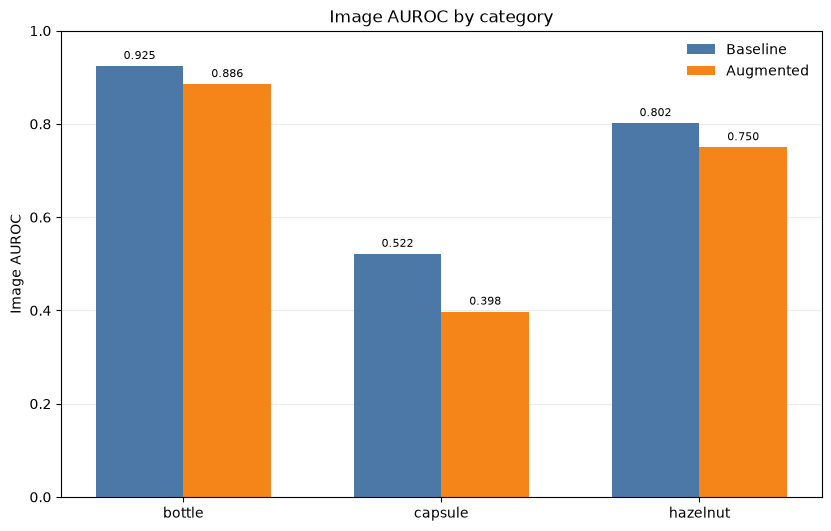

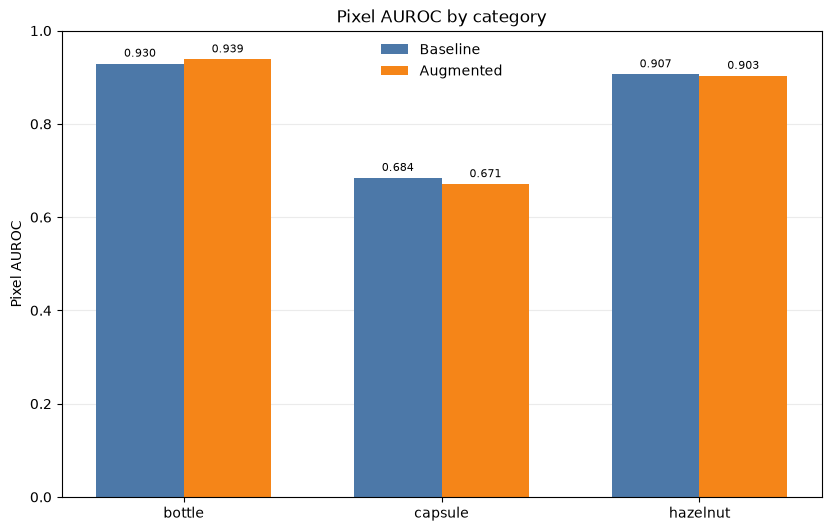

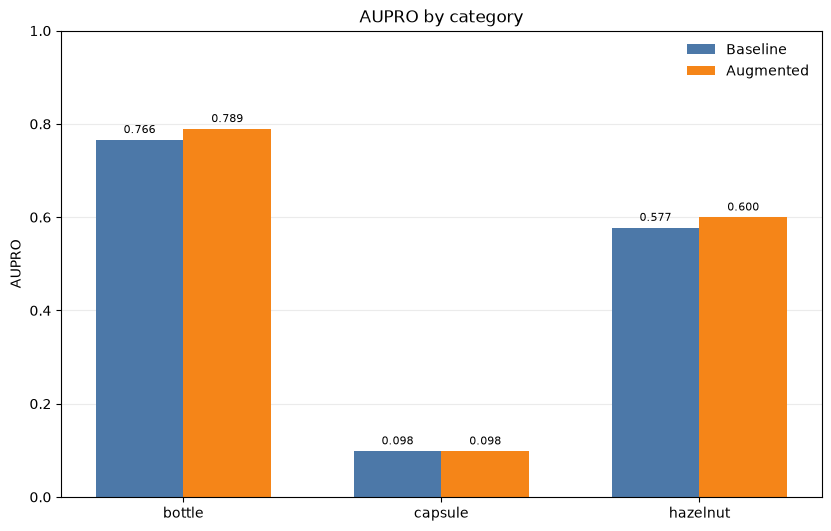

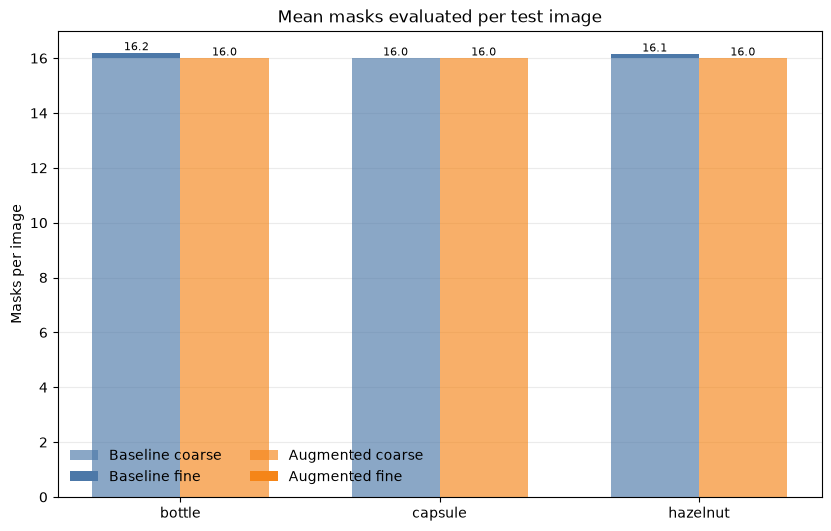

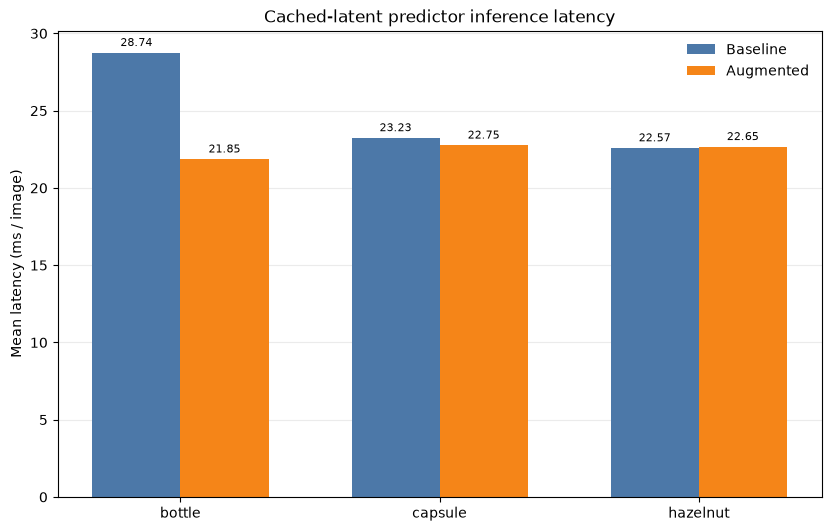

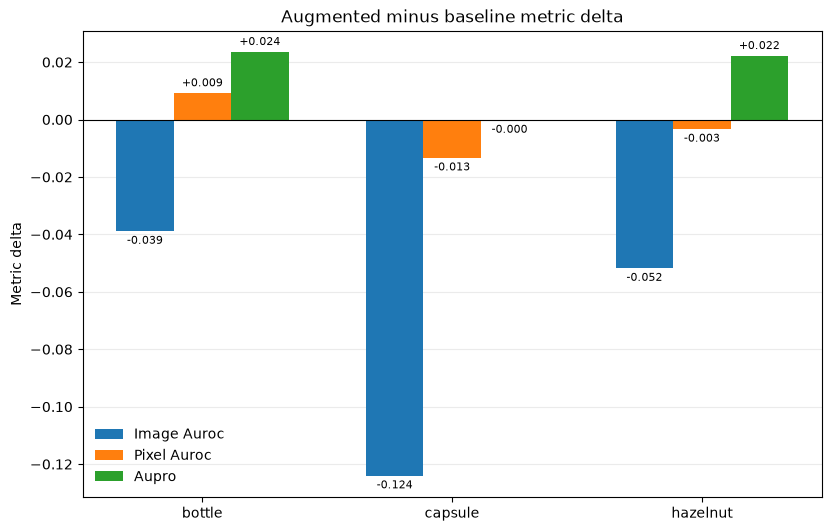

Figures saved under c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\evaluation\figures


In [9]:
COLORS = {'baseline': '#4C78A8', 'augmented': '#F58518'}
CATEGORY_ORDER = list(CATEGORIES)
comparison_csv = OUTPUT_ROOT / 'predictor_comparison.csv'
per_image_csv = OUTPUT_ROOT / 'predictor_comparison_per_image.csv'
summary_json = OUTPUT_ROOT / 'evaluation_summary.json'
figure_paths = [
    FIGURE_ROOT / 'image_auroc_comparison.png',
    FIGURE_ROOT / 'pixel_auroc_comparison.png',
    FIGURE_ROOT / 'aupro_comparison.png',
    FIGURE_ROOT / 'masks_comparison.png',
    FIGURE_ROOT / 'latency_comparison.png',
    FIGURE_ROOT / 'metric_delta_comparison.png',
]
existing_outputs = [path for path in [comparison_csv, per_image_csv, summary_json, *figure_paths] if path.exists()]
if existing_outputs:
    raise FileExistsError('Refusing to overwrite existing evaluation output(s): ' + ', '.join(map(str, existing_outputs)))


def paired_metric_plot(metric, title, ylabel, filename):
    x = np.arange(len(CATEGORY_ORDER))
    width = 0.34
    fig, ax = plt.subplots(figsize=(8.2, 5.2), constrained_layout=True)
    for offset, predictor_type in ((-width / 2, 'baseline'), (width / 2, 'augmented')):
        values = [
            float(comparison_df.loc[(comparison_df['category'] == category) & (comparison_df['predictor'] == predictor_type), metric].iloc[0])
            for category in CATEGORY_ORDER
        ]
        bars = ax.bar(x + offset, values, width, color=COLORS[predictor_type], label=predictor_type.capitalize())
        ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
    ax.set(title=title, ylabel=ylabel, xticks=x, xticklabels=CATEGORY_ORDER)
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)
    fig.savefig(FIGURE_ROOT / filename, dpi=300, bbox_inches='tight')
    plt.show()

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
paired_metric_plot('image_auroc', 'Image AUROC by category', 'Image AUROC', 'image_auroc_comparison.png')
paired_metric_plot('pixel_auroc', 'Pixel AUROC by category', 'Pixel AUROC', 'pixel_auroc_comparison.png')
paired_metric_plot('aupro', 'AUPRO by category', 'AUPRO', 'aupro_comparison.png')

x = np.arange(len(CATEGORY_ORDER))
width = 0.34
fig, ax = plt.subplots(figsize=(8.2, 5.2), constrained_layout=True)
for offset, predictor_type in ((-width / 2, 'baseline'), (width / 2, 'augmented')):
    subset = comparison_df.set_index(['category', 'predictor'])
    coarse = [float(subset.loc[(category, predictor_type), 'coarse_masks_per_image']) for category in CATEGORY_ORDER]
    fine = [float(subset.loc[(category, predictor_type), 'fine_masks_per_image']) for category in CATEGORY_ORDER]
    bars = ax.bar(x + offset, coarse, width, color=COLORS[predictor_type], alpha=0.65, label=f'{predictor_type.capitalize()} coarse')
    ax.bar(x + offset, fine, width, bottom=coarse, color=COLORS[predictor_type], label=f'{predictor_type.capitalize()} fine')
    for index, (coarse_count, fine_count) in enumerate(zip(coarse, fine, strict=True)):
        ax.text(x[index] + offset, coarse_count + fine_count, f'{coarse_count + fine_count:.1f}', ha='center', va='bottom', fontsize=8)
ax.set(title='Mean masks evaluated per test image', ylabel='Masks per image', xticks=x, xticklabels=CATEGORY_ORDER)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncols=2)
fig.savefig(FIGURE_ROOT / 'masks_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8.2, 5.2), constrained_layout=True)
for offset, predictor_type in ((-width / 2, 'baseline'), (width / 2, 'augmented')):
    values = [float(comparison_df.loc[(comparison_df['category'] == category) & (comparison_df['predictor'] == predictor_type), 'latency_ms'].iloc[0]) for category in CATEGORY_ORDER]
    bars = ax.bar(x + offset, values, width, color=COLORS[predictor_type], label=predictor_type.capitalize())
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)
ax.set(title='Cached-latent predictor inference latency', ylabel='Mean latency (ms / image)', xticks=x, xticklabels=CATEGORY_ORDER)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.savefig(FIGURE_ROOT / 'latency_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8.2, 5.2), constrained_layout=True)
delta_plot_metrics = ('image_auroc', 'pixel_auroc', 'aupro')
delta_width = 0.23
for index, metric in enumerate(delta_plot_metrics):
    positions = x + (index - 1) * delta_width
    bars = ax.bar(positions, delta_df[metric].to_numpy(dtype=float), delta_width, label=metric.replace('_', ' ').title())
    ax.bar_label(bars, fmt='%+.3f', padding=3, fontsize=8)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Augmented minus baseline metric delta', ylabel='Metric delta', xticks=x, xticklabels=CATEGORY_ORDER)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.savefig(FIGURE_ROOT / 'metric_delta_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Figures saved under {FIGURE_ROOT}')

## 11. Save machine-readable results

The comparison artifacts identify each predictor and exact checkpoint path. Existing result files are never overwritten.

In [10]:
existing_outputs = [path for path in [comparison_csv, per_image_csv, summary_json] if path.exists()]
if existing_outputs:
    raise FileExistsError('Refusing to overwrite existing evaluation output(s): ' + ', '.join(map(str, existing_outputs)))
missing_figures = [path for path in figure_paths if not path.is_file()]
if missing_figures:
    raise FileNotFoundError('Expected measured comparison figure(s) are missing: ' + ', '.join(map(str, missing_figures)))

comparison_df.to_csv(comparison_csv, index=False)
pd.DataFrame(per_image_rows).to_csv(per_image_csv, index=False)
summary_payload = {
    'evaluation_label': 'Uncalibrated/default inference configuration',
    'predictor_identity': 'baseline vs augmented',
    'test_split_only': True,
    'test_data_used_for_calibration_or_checkpoint_selection': False,
    'encoder': {'name': ENCODER_NAME, 'checkpoint_path': str(ENCODER_CHECKPOINT), 'sha256': ENCODER_SHA256},
    'dataset_roots': {category: str(DATASET_ROOTS[category]) for category in CATEGORIES},
    'test_cache_root': str(TEST_CACHE_ROOT),
    'inference': {
        'mode': INFERENCE_MODE,
        'masking_settings': MASKING_SETTINGS,
        'tau': MASKING_SETTINGS['threshold'],
        'lambda': MASKING_SETTINGS['lam'],
        'coarse_window_size': MASKING_SETTINGS['coarse_size'],
        'fine_window_size': MASKING_SETTINGS['fine_size'],
        'fine_window_behavior': 'production adaptive selector; fine windows selected from coarse scores above tau' if INFERENCE_MODE == 'adaptive' else 'production mode behavior',
        'interpolation': 'bilinear, align_corners=False',
        'image_score_normalization': 'max(fused patch scores) / production mode-and-lambda upper bound',
        'pixel_scores': 'raw; no UI per-image min-max normalization',
        'decision_threshold': None,
    },
    'metric_implementation': 'ijepa_ad.evaluation.metrics (image_auroc, pixel_auroc, aupro)',
    'results': aggregate_rows,
    'augmentation_delta': delta_rows,
    'checkpoint_provenance': {
        f'{category}/{predictor_type}': CHECKPOINT_INFO[(category, predictor_type)]
        for category in CATEGORIES
        for predictor_type in PREDICTOR_TYPES
    },
    'outputs': {
        'comparison_csv': str(comparison_csv),
        'per_image_csv': str(per_image_csv),
        'figures': [str(path) for path in figure_paths],
    },
}
summary_json.write_text(json.dumps(summary_payload, indent=2, sort_keys=True) + '\n', encoding='utf-8')
print(f'Comparison table: {comparison_csv}')
print(f'Per-image results: {per_image_csv}')
print(f'Summary JSON: {summary_json}')
print(f'Figures: {FIGURE_ROOT}')

Comparison table: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\evaluation\predictor_comparison.csv
Per-image results: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\evaluation\predictor_comparison_per_image.csv
Summary JSON: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\evaluation\evaluation_summary.json
Figures: c:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\evaluation\figures


## 12. Final sanity summary

AUROC/AUPRO increases indicate ranking improvement. Lower mask counts or latency indicate lower measured inference work. This is a descriptive test-set comparison; without confidence intervals or a separately defined calibration study, do not treat small differences as conclusive.

In [11]:
print('Baseline vs Augmented')
for category in CATEGORIES:
    base = next(row for row in aggregate_rows if row['category'] == category and row['predictor'] == 'baseline')
    aug = next(row for row in aggregate_rows if row['category'] == category and row['predictor'] == 'augmented')
    print(f'\n{category}:')
    for metric, title, digits in (
        ('image_auroc', 'Image AUROC', 4),
        ('pixel_auroc', 'Pixel AUROC', 4),
        ('aupro', 'AUPRO', 4),
        ('masks_per_image', 'Masks/image', 2),
        ('latency_ms', 'Latency (ms/image)', 2),
    ):
        before, after = base[metric], aug[metric]
        print(f'  {title}: {before:.{digits}f} -> {after:.{digits}f} ({after - before:+.{digits}f})')

primary_deltas = delta_df[['image_auroc', 'pixel_auroc', 'aupro']]
improved_categories, worse_categories, mixed_categories = [], [], []
for _, row in delta_df.iterrows():
    values = [row[metric] for metric in ('image_auroc', 'pixel_auroc', 'aupro')]
    if all(value >= 0 for value in values) and any(value > 0 for value in values):
        improved_categories.append(row['category'])
    elif all(value <= 0 for value in values) and any(value < 0 for value in values):
        worse_categories.append(row['category'])
    else:
        mixed_categories.append(row['category'])
print(f'\nImproved across all three ranking metrics: {improved_categories or "none"}')
print(f'Worse across all three ranking metrics: {worse_categories or "none"}')
print(f'Mixed/no-change ranking results: {mixed_categories or "none"}')
work_deltas = delta_df[['masks_per_image', 'latency_ms']].to_numpy(dtype=float)
if np.all(work_deltas < 0):
    work_summary = 'measured mask work and latency both decreased'
elif np.all(work_deltas > 0):
    work_summary = 'measured mask work and latency both increased'
else:
    work_summary = 'measured mask work and latency changed by different amounts across categories'
print(f'Inference work: {work_summary}.')
print('Conclusion: descriptive results only; treat the comparison as inconclusive pending uncertainty estimates and any separately planned calibration/experiments.')
print('Fairness check: both predictors used the same official test images/masks, encoder SHA, preprocessing, production inference mode/settings, score interpolation, and metric implementation; the intended difference is original-only vs original-plus-augmented nominal training data.')
print(f'Artifacts: {OUTPUT_ROOT}')

Baseline vs Augmented

bottle:
  Image AUROC: 0.9246 -> 0.8857 (-0.0389)
  Pixel AUROC: 0.9295 -> 0.9387 (+0.0092)
  AUPRO: 0.7657 -> 0.7893 (+0.0236)
  Masks/image: 16.19 -> 16.00 (-0.19)
  Latency (ms/image): 28.74 -> 21.85 (-6.89)

capsule:
  Image AUROC: 0.5217 -> 0.3977 (-0.1241)
  Pixel AUROC: 0.6845 -> 0.6711 (-0.0133)
  AUPRO: 0.0981 -> 0.0979 (-0.0002)
  Masks/image: 16.00 -> 16.00 (+0.00)
  Latency (ms/image): 23.23 -> 22.75 (-0.47)

hazelnut:
  Image AUROC: 0.8021 -> 0.7504 (-0.0518)
  Pixel AUROC: 0.9067 -> 0.9034 (-0.0033)
  AUPRO: 0.5774 -> 0.5996 (+0.0222)
  Masks/image: 16.15 -> 16.00 (-0.15)
  Latency (ms/image): 22.57 -> 22.65 (+0.08)

Improved across all three ranking metrics: none
Worse across all three ranking metrics: ['capsule']
Mixed/no-change ranking results: ['bottle', 'hazelnut']
Inference work: measured mask work and latency changed by different amounts across categories.
Conclusion: descriptive results only; treat the comparison as inconclusive pending unce